In [73]:
import pandas as pd
import numpy as np
from scipy.sparse import hstack, csr_matrix

from pathlib import Path

import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from sklearn.naive_bayes import MultinomialNB

from sklearn.feature_selection import f_classif
from statsmodels.stats.outliers_influence import variance_inflation_factor

from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler, PowerTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.cluster import KMeans
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedGroupKFold, PredefinedSplit
from sklearn.metrics import classification_report, f1_score, accuracy_score

In [2]:
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

In [3]:
df = pd.read_csv(Path("/mnt/data/datasets/spotify_tracks/tracks.csv"))

## 1.1 Data Exploration

### 1.1.1 Dataset Overview

In [5]:
df.head()

,Unnamed: 0,track_name,track_id,album_name,album_id,album_image,album_release_date,album_release_date_precision,artist_name,artist_id,popularity,duration_ms,explicit,preview_url,genre,acousticness,danceability,energy,instrumentalness,key,liveness,loudness,mode,speechiness,tempo,time_signature,valence,database_shard_id,duration_seconds,duration_minutes
0,0,"Divenire: No. 9, Fly - Intouchables",5u5scm02d5wN6nWFKuqEUK,Discover The Great Classics,6HKSdjtjJGtxmeUrkhSCSf,https://i.scdn.co/image/ab67616d0000b2737e7f92...,1950,year,Jeroen van Veen,7o7D77HMHvg1sAmtryKoVy,2,265653,False,https://p.scdn.co/mp3-preview/81f71ca4ea95503e...,ambient,0.990,0.184,0.03270,0.877,1,0.0996,-28.184,0,0.0366,168.133,3,0.0351,0,265.653,4.427550
1,1,Spiegel im Spiegel - Heaven,1wV4SNFEXWawsyjBCGwkiw,Discover The Great Classics,6HKSdjtjJGtxmeUrkhSCSf,https://i.scdn.co/image/ab67616d0000b2737e7f92...,1950,year,Jeroen van Veen,7o7D77HMHvg1sAmtryKoVy,0,349120,False,https://p.scdn.co/mp3-preview/040ea9c848708316...,ambient,0.985,0.250,0.01480,0.971,5,0.0669,-30.646,1,0.0375,136.864,5,0.0394,0,349.120,5.818667
2,2,Truman Sleeps - The Trumanshow,4gYub3T80gNfU9F4Df98AR,Discover The Great Classics,6HKSdjtjJGtxmeUrkhSCSf,https://i.scdn.co/image/ab67616d0000b2737e7f92...,1950,year,Jeroen van Veen,7o7D77HMHvg1sAmtryKoVy,1,128039,False,https://p.scdn.co/mp3-preview/e9a7cd955c89d480...,ambient,0.993,0.269,0.02110,0.883,5,0.1390,-24.620,0,0.0395,69.487,4,0.0411,0,128.039,2.133983
3,3,The Heart Askes Pleasure First - The Piano,6sXRgSAQsySTM7kH1pM07Y,Discover The Great Classics,6HKSdjtjJGtxmeUrkhSCSf,https://i.scdn.co/image/ab67616d0000b2737e7f92...,1950,year,Jeroen van Veen,7o7D77HMHvg1sAmtryKoVy,0,190960,False,https://p.scdn.co/mp3-preview/9a33da62792f8277...,ambient,0.995,0.230,0.13800,0.885,4,0.1010,-19.591,0,0.0371,165.197,3,0.1710,0,190.960,3.182667
4,4,3 Gymnopédies: I. Lent et douloureux,7Eytd0e0mNFiSWIE132H76,Discover The Great Classics,6HKSdjtjJGtxmeUrkhSCSf,https://i.scdn.co/image/ab67616d0000b2737e7f92...,1950,year,Jeroen van Veen,7o7D77HMHvg1sAmtryKoVy,4,338933,False,https://p.scdn.co/mp3-preview/d31979ca20bbd759...,ambient,0.995,0.611,0.00162,0.967,7,0.0817,-37.782,1,0.2860,134.237,3,0.5080,0,338.933,5.648883


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2112746 entries, 0 to 2112745
Data columns (total 30 columns):
 #   Column                        Dtype  
---  ------                        -----  
 0   Unnamed: 0                    int64  
 1   track_name                    str    
 2   track_id                      str    
 3   album_name                    str    
 4   album_id                      str    
 5   album_image                   str    
 6   album_release_date            str    
 7   album_release_date_precision  str    
 8   artist_name                   str    
 9   artist_id                     str    
 10  popularity                    int64  
 11  duration_ms                   int64  
 12  explicit                      bool   
 13  preview_url                   str    
 14  genre                         str    
 15  acousticness                  float64
 16  danceability                  float64
 17  energy                        float64
 18  instrumentalness              flo

### 1.1.2 Dataset Quality

In [4]:
df.duplicated().sum()

np.int64(0)

In [5]:
df.isnull().sum()

Unnamed: 0                           0
track_name                           6
track_id                             0
album_name                           6
album_id                             0
album_image                        491
album_release_date                   0
album_release_date_precision         0
artist_name                         17
artist_id                            0
popularity                           0
duration_ms                          0
explicit                             0
preview_url                     325237
genre                                0
acousticness                         0
danceability                         0
energy                               0
instrumentalness                     0
key                                  0
liveness                             0
loudness                             0
mode                                 0
speechiness                          0
tempo                                0
time_signature           

In [7]:
df = df.drop(columns=['Unnamed: 0', 'database_shard_id', 'preview_url', 'album_id', 'track_id', 'album_image', 'album_release_date', 'album_release_date_precision', 'artist_name', 'artist_id', 'duration_ms', 'duration_minutes'])

In [8]:
df = df.dropna()

In [9]:
df["explicit"] = df["explicit"].astype(int)

### 1.1.3 Feature Relationship and Distribution

In [9]:
df.describe()

,popularity,explicit,acousticness,danceability,energy,instrumentalness,key,liveness,loudness,mode,speechiness,tempo,time_signature,valence,duration_seconds
count,2.112736e+06,2.112736e+06,2.112736e+06,2.112736e+06,2.112736e+06,2.112736e+06,2.112736e+06,2.112736e+06,2.112736e+06,2.112736e+06,2.112736e+06,2.112736e+06,2.112736e+06,2.112736e+06,2.112736e+06
mean,1.377672e+01,4.922858e-02,3.921944e-01,5.285379e-01,5.833878e-01,2.188482e-01,5.248915e+00,2.245102e-01,-1.025286e+01,6.620699e-01,8.522004e-02,1.202604e+02,3.873687e+00,4.874519e-01,2.494331e+02
std,1.463674e+01,2.163450e-01,3.669645e-01,1.797403e-01,2.759472e-01,3.469544e-01,3.532850e+00,2.025182e-01,5.799943e+00,4.730047e-01,1.185055e-01,2.977376e+01,4.701898e-01,2.726175e-01,1.453019e+02
min,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.970000e-05,0.000000e+00,0.000000e+00,2.960000e-03,-5.810000e+01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,4.860000e-01
25%,1.000000e+00,0.000000e+00,2.210000e-02,4.040000e-01,3.700000e-01,1.180000e-06,2.000000e+00,9.770000e-02,-1.290100e+01,0.000000e+00,3.570000e-02,9.711000e+01,4.000000e+00,2.560000e-01,1.795000e+02
50%,9.000000e+00,0.000000e+00,2.890000e-01,5.390000e-01,6.130000e-01,8.260000e-04,5.000000e+00,1.370000e-01,-8.900000e+00,1.000000e+00,4.720000e-02,1.199840e+02,4.000000e+00,4.840000e-01,2.268860e+02
75%,2.200000e+01,0.000000e+00,7.600000e-01,6.630000e-01,8.260000e-01,4.060000e-01,8.000000e+00,2.910000e-01,-6.117000e+00,1.000000e+00,7.850000e-02,1.385590e+02,4.000000e+00,7.150000e-01,2.878800e+02
max,1.000000e+02,1.000000e+00,9.960000e-01,9.950000e-01,1.000000e+00,1.000000e+00,1.100000e+01,1.000000e+00,6.172000e+00,1.000000e+00,9.690000e-01,2.499930e+02,5.000000e+00,1.000000e+00,7.200006e+03


In [10]:
print(df['genre'].value_counts().to_string())

genre
classical            48143
blues                45752
indian               43616
german               43002
french               40832
country              38847
british              38476
alt-rock             37065
disco                34808
brazil               34482
opera                34056
turkish              33997
pop-film             32268
dance                32059
jazz                 31340
ambient              30898
gospel               30422
latin                30368
spanish              30298
folk                 29167
funk                 28505
guitar               27087
bluegrass            27073
k-pop                26456
j-pop                26114
swedish              25838
dub                  25670
acoustic             25669
children             25597
new-age              25164
mpb                  25108
anime                24623
black-metal          23511
dancehall            23477
forro                23266
cantopop             23036
death-metal          2

In [10]:
df_numerical = df.select_dtypes(include='number')

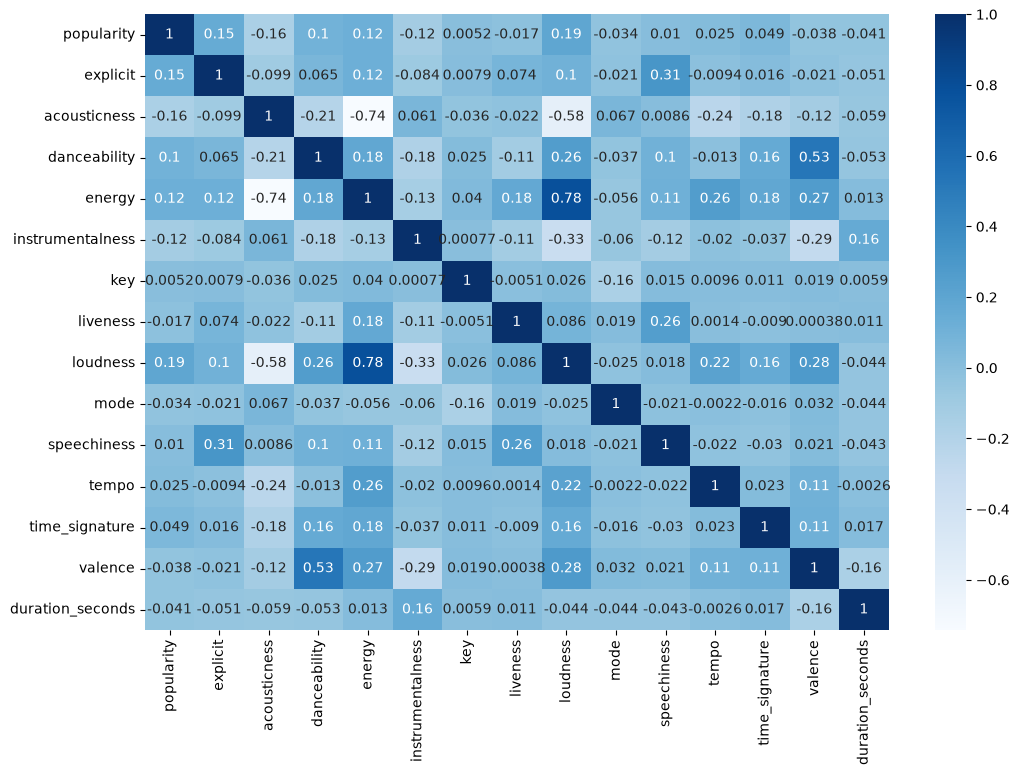

In [11]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    df_numerical.corr(),
    annot=True,
    cmap='Blues'
)

plt.show()

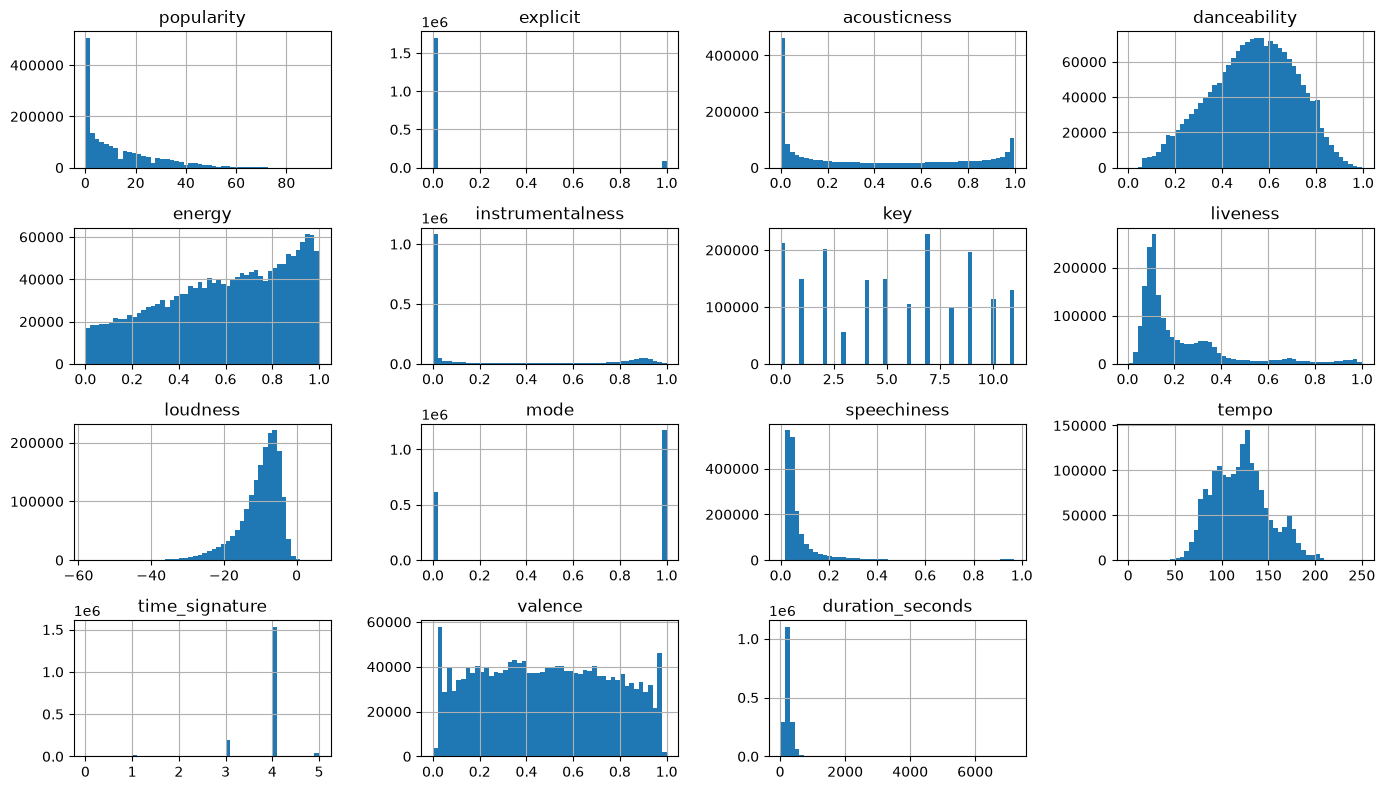

In [12]:
df_numerical.hist(bins=50, figsize=(14, 8))

plt.tight_layout()
plt.show()

### 1.1.4 Feature Distribution and Class Imbalance

The histograms above show that some continous numerical features have asymmetric distributions. Skewness describes the asymmetry of a data distribution around its mean.
This could negatively impact the performance of models that assume normally distributed data or are sensitive to the variance of input features, such as linear regression, principal component analysis (PCA), and support vector machines (SVMs).
- **Positive skewness (right-skewed):** the distribution has a longer tail towards higher values.
- **Negative skewness (left-skewed):** the distribution has a longer tail towards lower values.

Based on the histograms, the following features appear to be positively skewed:
- `duration_seconds`
- `liveness`
- `instrumentalness`
- `popularity`

The following features appear to be negatively skewed:
- `energy`
- `loudness`

The skewness of `acousticness` is less clear from the histogram alone and will be investigated further in the next step.

In [13]:
df_numerical.skew()

popularity          1.214319
explicit            4.166496
acousticness        0.423765
danceability       -0.225347
energy             -0.369376
instrumentalness    1.123735
key                -0.003725
liveness            1.953287
loudness           -1.436084
mode               -0.656765
speechiness         4.721345
tempo               0.344123
time_signature     -3.153546
valence             0.054440
duration_seconds    8.817976
dtype: float64

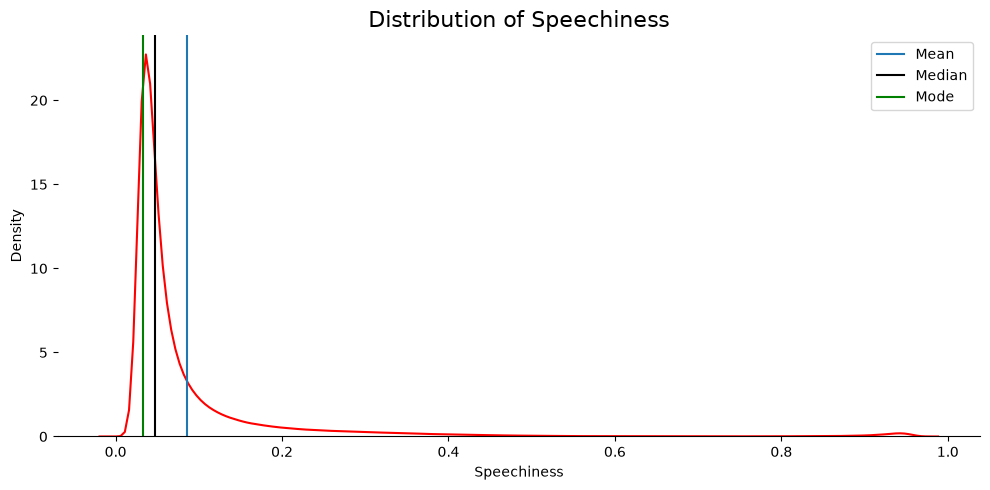

In [16]:
# Find the mean, median, mode
mean_value = df["speechiness"].mean()
median_value = df["speechiness"].median()
mode_value = df["speechiness"].mode().iloc[0]

plt.figure(figsize=(10, 5))
sns.kdeplot(x=df['speechiness'], color="red")

# Add vertical lines at the position of mean, median, mode
plt.axvline(mean_value, label="Mean")
plt.axvline(median_value, color="black", label="Median")
plt.axvline(mode_value, color="green", label="Mode")

plt.title("Distribution of Speechiness", fontsize=16)
plt.xlabel("Speechiness")
plt.ylabel("Density")
sns.despine(top=True, right=True, left=True)
plt.legend()
plt.tight_layout()
plt.show()


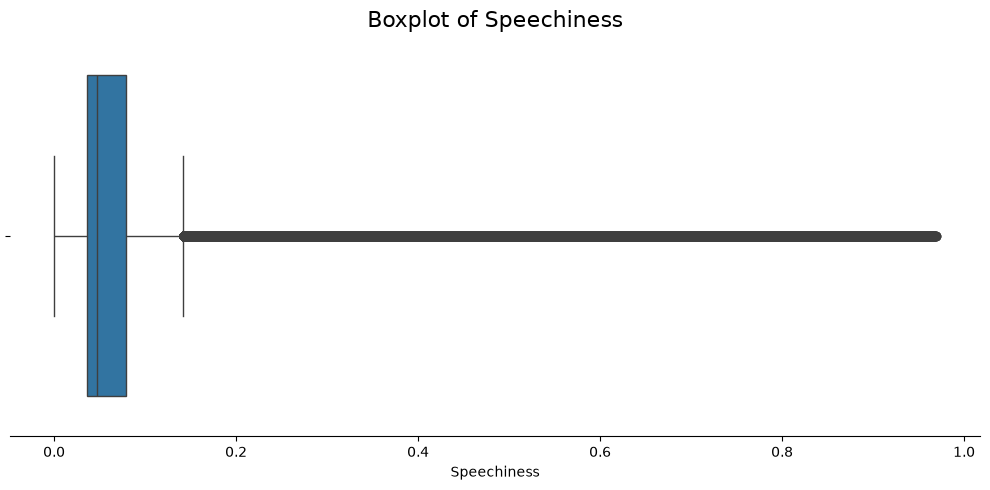

In [17]:
plt.figure(figsize=(10, 5))

sns.boxplot(x=df["speechiness"])

plt.title("Boxplot of Speechiness", fontsize=16)
plt.xlabel("Speechiness")
sns.despine(top=True, right=True, left=True)
plt.tight_layout()
plt.show()

The KDE plot (*continous*) and boxplot of speechiness confirm its positive skewness of 4.77, as we saw on the histogram (*bins*). Most observations are concentrated at **lower values**, with a **long tail** extending towards higher values, on the right side of the peak.

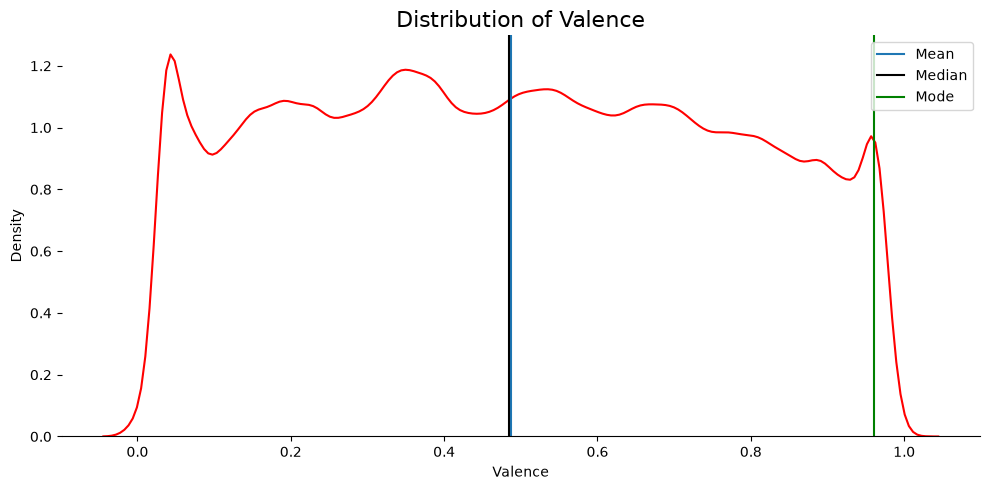

In [19]:
# Find the mean, median, mode
mean_value = df["valence"].mean()
median_value = df["valence"].median()
mode_value = df["valence"].mode().iloc[0]

plt.figure(figsize=(10, 5))
sns.kdeplot(x=df['valence'], color="red")

# Add vertical lines at the position of mean, median, mode
plt.axvline(mean_value, label="Mean")
plt.axvline(median_value, color="black", label="Median")
plt.axvline(mode_value, color="green", label="Mode")

plt.title("Distribution of Valence", fontsize=16)
plt.xlabel("Valence")
plt.ylabel("Density")
sns.despine(top=True, right=True, left=True)
plt.legend()
plt.tight_layout()
plt.show()


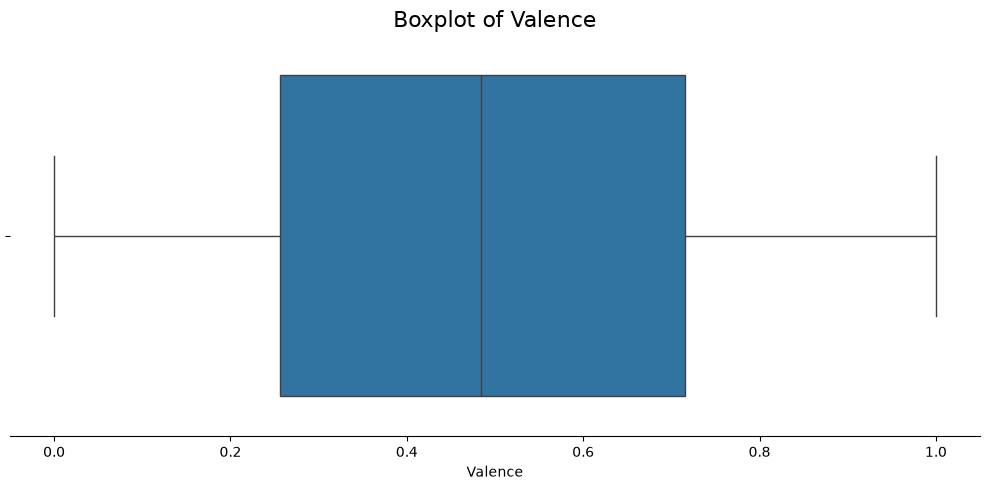

In [20]:
plt.figure(figsize=(10, 5))

sns.boxplot(x=df["valence"])

plt.title("Boxplot of Valence", fontsize=16)
plt.xlabel("Valence")
sns.despine(top=True, right=True, left=True)
plt.tight_layout()
plt.show()

The KDE plot and boxplot of valence show a relatively symmetric distribution, consistent with its near-zero skewness of 0.05, as observed in the histogram. The mean and median are close together, and the distribution does not show a pronounced tail towards either lower or higher values.

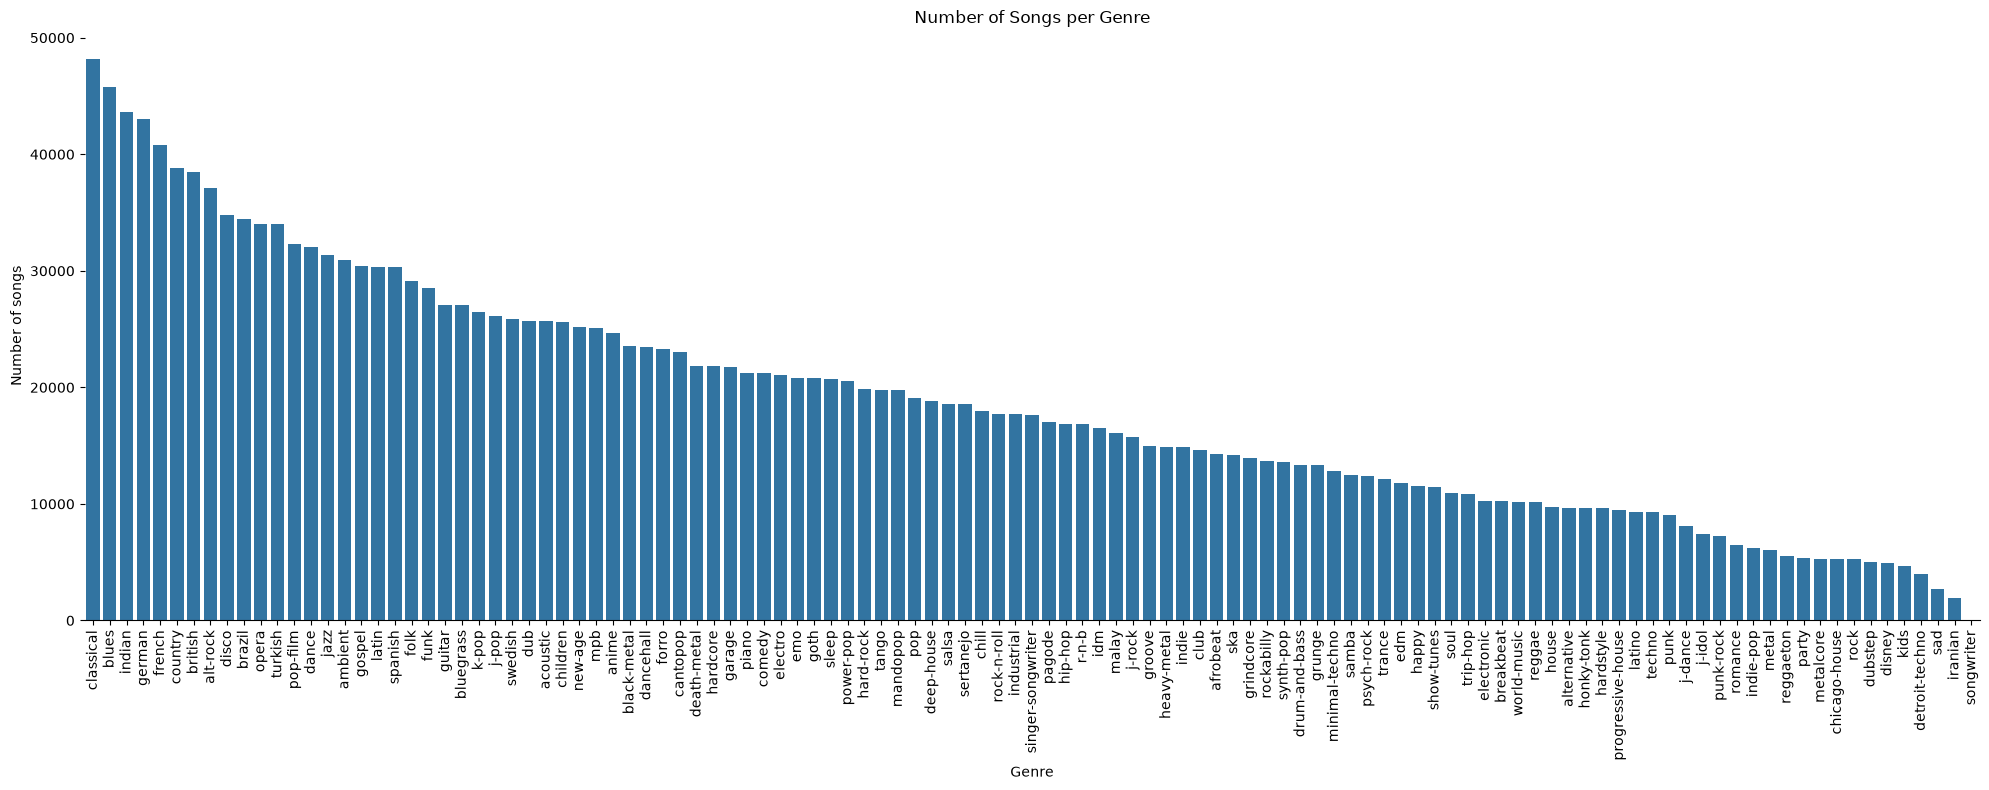

In [17]:
plt.figure(figsize=(20, 8))

genre_order = df["genre"].value_counts().index

ax = sns.countplot(
    data=df,
    x="genre",
    order=genre_order
)

plt.xticks(rotation=90)
plt.xlabel("Genre")
plt.ylabel("Number of songs")
plt.title("Number of Songs per Genre")
sns.despine(top=True, right=True, left=True)
plt.tight_layout()
plt.show()

The countplot shows the distribution of tracks across genres, ordered from most frequent to least frequent. The number of tracks varies considerably between genres: classical is the most represented genre, with 48,143 tracks, whereas songwriter has only 66 tracks. This indicates a substantial class imbalance, which may cause the classification model to perform better on well-represented genres than on underrepresented ones.

### 1.1.5 Correlation and Multicollinearity

In [14]:
le = LabelEncoder()

In [15]:
df['genre'] = le.fit_transform(df["genre"])

In the next step we calculate the **ANOVA F-statistic**, as our input variables are numerical and output variables are non-ordinal categorical. This informs us what features correlate highly with the output variable, genre.

For more information, see [How to Choose a Feature Selection Method For Machine Learning](https://machinelearningmastery.com/feature-selection-with-real-and-categorical-data/).

In [20]:
f_statistic, _ = f_classif(df_numerical, df['genre'])

anova_df = pd.DataFrame({
    "feature": df_numerical.columns,
    "F-value": f_statistic
}).sort_values("F-value", ascending=False)

anova_df

,feature,F-value
2,acousticness,15341.086211
4,energy,12723.796624
10,speechiness,12482.232343
8,loudness,11720.552705
3,danceability,9762.619755
5,instrumentalness,9546.905802
13,valence,7157.059485
0,popularity,5811.233903
1,explicit,4485.733723
14,duration_seconds,2018.075839


The highest F-values observed are `acousticness`, `speechiness` and `energy`.

We calculate the **Variance Inflation Factor** (VIF) to detect multicollinearity between the numerical input variables. This indicates whether some features contain overlapping information, and could therefore mislead the model.

In [21]:
vif_df = pd.DataFrame({
    "feature": df_numerical.columns,
    "VIF": [
        variance_inflation_factor(df_numerical.values, i)
        for i in range(df_numerical.shape[1])
    ]
}).sort_values("VIF", ascending=False)

vif_df

,feature,VIF
4,energy,4.806833
8,loudness,3.310619
2,acousticness,2.554363
13,valence,1.739783
3,danceability,1.667655
5,instrumentalness,1.315746
10,speechiness,1.268928
1,explicit,1.162053
7,liveness,1.160770
0,popularity,1.105421


A VIF value equal to 1 indicates **no multicollinearity**, while a VIF between 1 and 5 indicates a **moderate** level of multicollinearity. A VIF greater than 5 indicates potentially **problematic** multicollinearity.

The highest VIF values were observed for *energy* and *loudness*. Both values are below the threshold of 5, indicating that there is no significant multicollinearity between the input features. Therefore, both features can remain in the dataset.

## 1.2 Data Preparation

### 1.2.1 Feature Engineering

We remove the `popularity` feature because it reflects a track's popularity rather than its intrinsic audio characteristics. 

Since our objective is to build a model that generalizes to unseen data, relying on popularity could be problematic, as a track's popularity may change over time. 

However, popularity could be useful in a recommendation system for a platform such as Spotify or Deezer, where it can provide additional information about user preferences and listening trends. In that context, the model could incorporate regularly updated popularity data and be retrained or updated as needed to account for changing trends.

In [16]:
df = df.drop(columns='popularity')

In [17]:
df['duration_seconds'] = df['duration_seconds'].round().astype(int)

In [18]:
df["album_songs"] = (
    df.groupby("album_name")["track_name"]
    .transform("count")
)

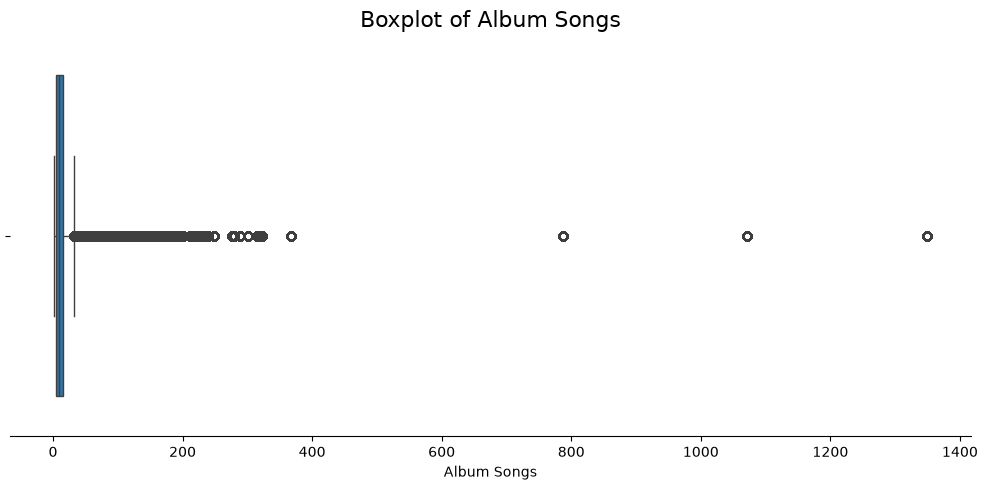

In [26]:
plt.figure(figsize=(10, 5))

sns.boxplot(x=df['album_songs'])

plt.title("Boxplot of Album Songs", fontsize=16)
plt.xlabel("Album Songs")
sns.despine(top=True, right=True, left=True)
plt.tight_layout()
plt.show()

### 1.2.2 Feature Transformation

In [27]:
X = df.drop(columns='genre')
y = df['genre']

To split our data we chose the strategy to have 80% as training data set, then a combination of a 10% validation set and a 10% test set.

In [28]:
groups = X['album_name']

In [29]:
splitter = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [30]:
train_idx, remaining_idx = next(
    splitter.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx]
y_train = y.iloc[train_idx]

X_remaining = X.iloc[remaining_idx]
y_remaining = y.iloc[remaining_idx]

In [39]:
splitter_remaining = StratifiedGroupKFold(
    n_splits=2,
    shuffle=True,
    random_state=42
)

In [40]:
groups_remaining = groups.iloc[remaining_idx]

In [41]:
validation_idx, test_idx = next(
    splitter_remaining.split(
        X_remaining,
        y_remaining,
        groups=groups_remaining
    )
)

X_validation = X_remaining.iloc[validation_idx]
y_validation = y_remaining.iloc[validation_idx]

X_test = X_remaining.iloc[test_idx]
y_test = y_remaining.iloc[test_idx]

In [42]:
print(f"Train:      {len(X_train):,} ({len(X_train) / len(X):.1%})")
print(f"Validation: {len(X_validation):,} ({len(X_validation) / len(X):.1%})")
print(f"Test:       {len(X_test):,} ({len(X_test) / len(X):.1%})")

Train:      1,429,640 (80.0%)
Validation: 178,706 (10.0%)
Test:       178,706 (10.0%)


In [50]:
pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(token_pattern=r"(?u)\b[^\W\d_]+\b", stop_words="english")),
    ("clf", MultinomialNB())
])

In [57]:
parameters = {
    "tfidf__ngram_range": [(1, 1), (1, 2), (1, 3)],
    "tfidf__max_features": [1000],
    "tfidf__min_df": [2, 3, 5, 8, 10, 15],
    "tfidf__max_df": [0.5],
}

In [65]:
X_tuning = np.concatenate([
    X_train[["track_name", "album_name"]].agg(" ".join, axis=1).to_numpy(),
    X_validation[["track_name", "album_name"]].agg(" ".join, axis=1).to_numpy()
])

y_tuning = np.concatenate([
    y_train.to_numpy(),
    y_validation.to_numpy()
])

# -1 = training sample, 0 = validation sample
test_fold = np.concatenate([
    np.full(len(X_train), -1),
    np.zeros(len(X_validation), dtype=int)
])

validation_split = PredefinedSplit(test_fold)

In [66]:
grid_search = GridSearchCV(
    pipeline,
    parameters,
    cv=validation_split,
    scoring="f1_macro",
    verbose=2,
    n_jobs=10
)

In [67]:
grid_search.fit(X_tuning, y_tuning)

Fitting 1 folds for each of 18 candidates, totalling 18 fits
[CV] END tfidf__max_df=0.5, tfidf__max_features=1000, tfidf__min_df=2, tfidf__ngram_range=(1, 1); total time=  10.6s
[CV] END tfidf__max_df=0.5, tfidf__max_features=1000, tfidf__min_df=3, tfidf__ngram_range=(1, 1); total time=  10.0s
[CV] END tfidf__max_df=0.5, tfidf__max_features=1000, tfidf__min_df=5, tfidf__ngram_range=(1, 1); total time=  14.2s
[CV] END tfidf__max_df=0.5, tfidf__max_features=1000, tfidf__min_df=8, tfidf__ngram_range=(1, 1); total time=  15.1s
[CV] END tfidf__max_df=0.5, tfidf__max_features=1000, tfidf__min_df=2, tfidf__ngram_range=(1, 2); total time=  25.6s
[CV] END tfidf__max_df=0.5, tfidf__max_features=1000, tfidf__min_df=5, tfidf__ngram_range=(1, 2); total time=  25.7s
[CV] END tfidf__max_df=0.5, tfidf__max_features=1000, tfidf__min_df=10, tfidf__ngram_range=(1, 1); total time=  12.4s
[CV] END tfidf__max_df=0.5, tfidf__max_features=1000, tfidf__min_df=3, tfidf__ngram_range=(1, 2); total time=  37.4s
[C

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...inomialNB())])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'tfidf__max_df': [0.5], 'tfidf__max_features': [1000], 'tfidf__min_df': [2, 3, ...], 'tfidf__ngram_range': [(1, ...), (1, ...), ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1_macro'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",10
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.","PredefinedSpl...e=(1901462,)))"
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",2
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple

In [68]:
print("Best parameters:", grid_search.best_params_)
print("Best validation macro-F1:", grid_search.best_score_)

Best parameters: {'tfidf__max_df': 0.5, 'tfidf__max_features': 1000, 'tfidf__min_df': 2, 'tfidf__ngram_range': (1, 1)}
Best validation macro-F1: 0.1215940389845403


In [ ]:
best_model = grid_search.best_estimator_

tfidf = best_model.named_steps["tfidf"]

vocabulary = tfidf.get_feature_names_out()

print(vocabulary[:100])

['acid' 'acoustic' 'act' 'action' 'acústico' 'adagio' 'age' 'ah' 'aida'
 'ain' 'air' 'al' 'album' 'alive' 'allegretto' 'allegro' 'alma' 'alright'
 'alternate' 'amar' 'ambient' 'america' 'american' 'amor' 'amour'
 'andante' 'angel' 'angels' 'animal' 'anniversary' 'anos' 'anthem'
 'anthology' 'ao' 'april' 'arena' 'aria' 'arias' 'arms' 'arr' 'art' 'asot'
 'au' 'auf' 'aus' 'away' 'años' 'b' 'baby' 'bach' 'bad' 'ball' 'ballads'
 'ballet' 'band' 'bang' 'bar' 'bass' 'battle' 'beach' 'beat' 'beats'
 'beautiful' 'beauty' 'beethoven' 'beginning' 'believe' 'bells' 'ben'
 'best' 'better' 'big' 'bir' 'bird' 'bit' 'black' 'blind' 'blood' 'blue'
 'bluegrass' 'blues' 'body' 'bom' 'bonus' 'boogie' 'book' 'boom' 'bop'
 'born' 'box' 'boy' 'boys' 'brahms' 'brasil' 'break' 'bridge' 'bright'
 'bring' 'broadway' 'broken']


The next step in our pipeline is feature transformation. As discussed in [Feature Distribution and Class Imbalance](#114-feature-distribution-and-class-imbalance), some numerical features exhibit skewness.

To address this, we use the **Yeo–Johnson transformation**, a power transformation that can reduce skewness in numerical features. We chose this method because our dataset contains both positive and negative values, and Yeo–Johnson can also handle zero values. Unlike the Box–Cox transformation, which requires strictly positive values, Yeo–Johnson can be applied to a wider range of numerical data.

We enable standardization as part of the transformation so that the resulting features have a mean of approximately zero and a standard deviation of approximately one. The transformation is fitted on the training data only to prevent data leakage.

For more information, see [Skewness Be Gone: Transformative Tricks for Data Scientists](https://machinelearningmastery.com/skewness-be-gone-transformative-tricks-for-data-scientists/).

In [35]:
df.skew(numeric_only=True)

explicit            4.167169
genre               0.268192
acousticness        0.372815
danceability       -0.218408
energy             -0.324786
instrumentalness    1.193549
key                -0.001305
liveness            1.960642
loudness           -1.393420
mode               -0.685284
speechiness         4.772691
tempo               0.360187
time_signature     -3.139470
valence             0.047029
duration_seconds    8.492846
dtype: float64

In [34]:
continuous_features = [
    'acousticness',
    'danceability',
    'energy',
    'instrumentalness',
    'liveness',
    'loudness',
    'speechiness',
    'tempo',
    'valence',
    'duration_seconds'
]

categorical_features = [
    "key",
    "time_signature",
]

binary_features = [
    'mode',
    'explicit'
]

skewed_features = [
    'instrumentalness',
    'liveness',
    'loudness',
    'speechiness',
    'duration_seconds',
    'album_songs'
]

In [35]:
non_skewed_features = [
    feature for feature in continuous_features
    if feature not in skewed_features
]

In [36]:
ss = StandardScaler().set_output(transform='pandas')
ohe = OneHotEncoder(sparse_output=False).set_output(transform='pandas')
pt = PowerTransformer(method='yeo-johnson', standardize=True).set_output(transform='pandas')
tiv = TfidfVectorizer(
    token_pattern=r"(?u)\b[^\W\d_]+\b", 
    stop_words="english",
    min_df=2, 
    max_df=0.5, 
    ngram_range=(1, 1),
    max_features=1000
)

In [44]:
X_train_skewed = pt.fit_transform(
    X_train[skewed_features]
)

X_validation_skewed = pt.transform(
    X_validation[skewed_features]
)

X_test_skewed = pt.transform(
    X_test[skewed_features]
)

In [45]:
X_train_non_skewed = ss.fit_transform(
    X_train[non_skewed_features]
)

X_validation_non_skewed = ss.transform(
    X_validation[non_skewed_features]
)

X_test_non_skewed = ss.transform(
    X_test[non_skewed_features]
)

In [46]:
X_train_cat = ohe.fit_transform(X_train[categorical_features])
X_validation_cat = ohe.transform(X_validation[categorical_features])
X_test_cat = ohe.transform(X_test[categorical_features])

In [52]:
X_train_text = tiv.fit_transform(
    X_train["track_name"] + " " + 
    X_train["album_name"]
)

X_validation_text = tiv.transform(
    X_validation["track_name"] + " " +
    X_validation["album_name"]
)

X_test_text = tiv.transform(
    X_test["track_name"] + " " +
    X_test["album_name"]
)

In [59]:
X_train_numeric_cat = pd.concat([X_train_skewed, X_train_non_skewed, X_train_cat], axis=1)
X_test_numeric_cat = pd.concat([X_test_skewed, X_test_non_skewed, X_test_cat], axis=1)
X_validation_numeric_cat = pd.concat([X_validation_skewed, X_validation_non_skewed, X_validation_cat], axis=1)

In [60]:
X_train_transformed = hstack(
    [csr_matrix(X_train_numeric_cat), X_train_text], format="csr"
)
X_validation_transformed = hstack(
    [csr_matrix(X_validation_numeric_cat), X_validation_text], format="csr"
)
X_test_transformed = hstack(
    [csr_matrix(X_test_numeric_cat), X_test_text], format="csr"
)

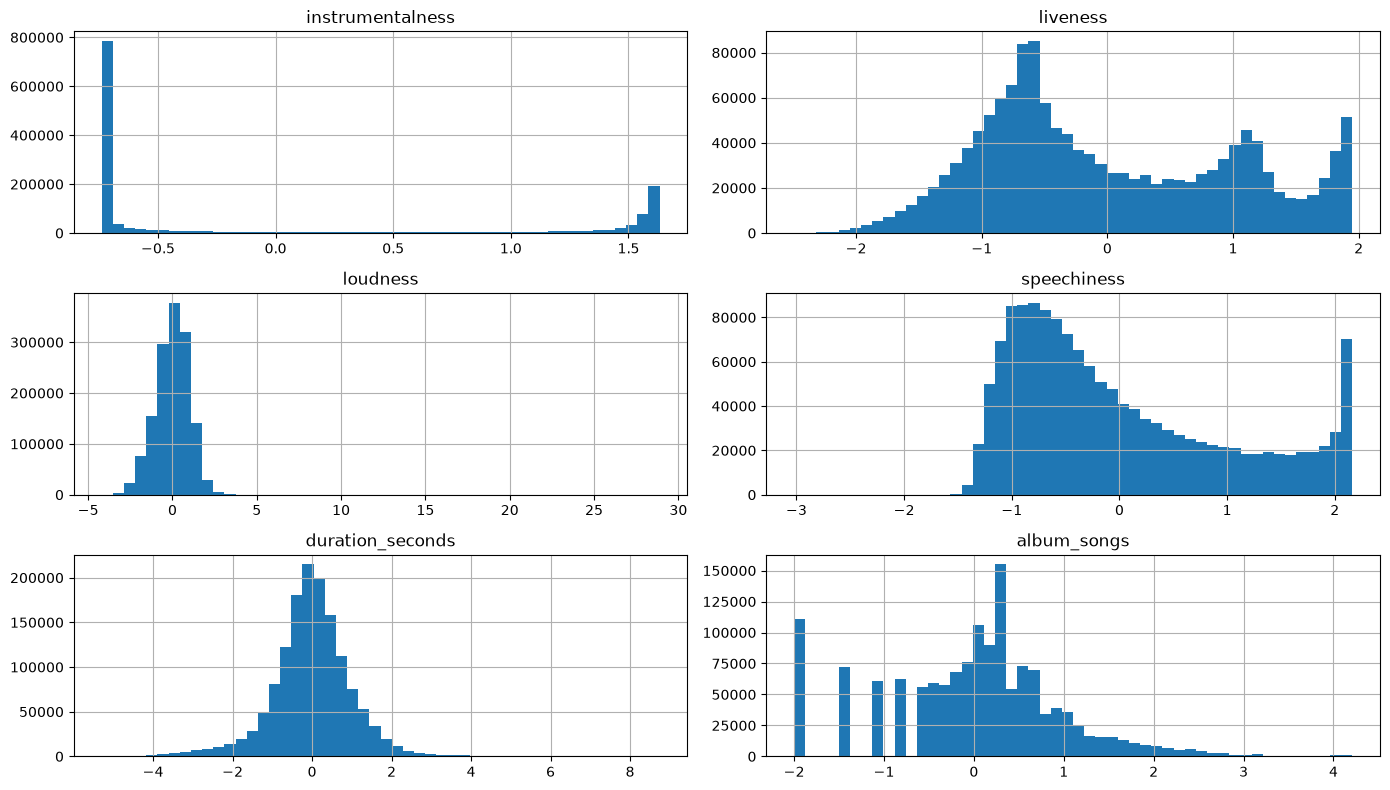

In [61]:
X_train_numeric_cat[skewed_features].hist(bins=50, figsize=(14, 8))

plt.tight_layout()
plt.show()

In [62]:
X_train_numeric_cat.skew(numeric_only=True)

instrumentalness      0.786368
liveness              0.360583
loudness              0.061986
speechiness           0.778970
duration_seconds      0.037132
album_songs          -0.022736
acousticness          0.424296
danceability         -0.224739
energy               -0.371110
tempo                 0.343335
valence               0.053320
key_0                 2.358771
key_1                 3.029662
key_2                 2.440891
key_3                 5.365336
key_4                 3.036925
key_5                 3.015177
key_6                 3.757956
key_7                 2.232653
key_8                 3.896230
key_9                 2.493332
key_10                3.570407
key_11                3.282056
time_signature_0    182.330775
time_signature_1      9.029187
time_signature_3      2.519251
time_signature_4     -2.071251
time_signature_5      6.847838
dtype: float64

In [63]:
pca = PCA().set_output(transform='pandas')

In [64]:
X_train_pca = pca.fit_transform(X_train_transformed)
X_validation_pca = pca.transform(X_validation_transformed)
X_test_pca = pca.transform(X_test_transformed)

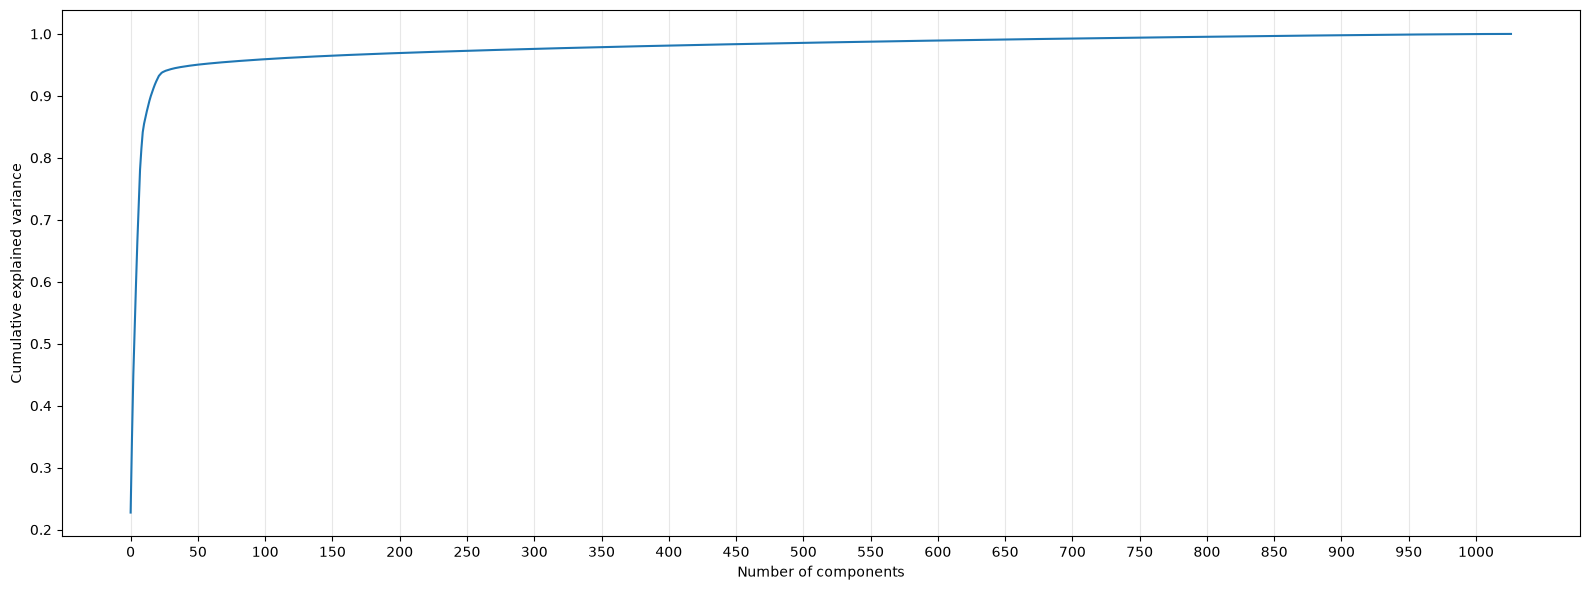

In [75]:
plt.figure(figsize=(16, 6))

plt.plot(np.cumsum(pca.explained_variance_ratio_))
plt.xticks(np.arange(0, len(pca.explained_variance_ratio_) + 1, 50))
plt.xlabel("Number of components")
plt.ylabel("Cumulative explained variance")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [66]:
X_train_pca.head()

,pca0,pca1,pca2,pca3,pca4,pca5,pca6,pca7,pca8,pca9,pca10,pca11,pca12,pca13,pca14,pca15,pca16,pca17,pca18,pca19,pca20,pca21,pca22,pca23,pca24,pca25,pca26,pca27,pca28,pca29,pca30,pca31,pca32,pca33,pca34,pca35,pca36,pca37,pca38,pca39,pca40,pca41,pca42,pca43,pca44,pca45,pca46,pca47,pca48,pca49,pca50,pca51,pca52,pca53,pca54,pca55,pca56,pca57,pca58,pca59,pca60,pca61,pca62,pca63,pca64,pca65,pca66,pca67,pca68,pca69,pca70,pca71,pca72,pca73,pca74,pca75,pca76,pca77,pca78,pca79,pca80,pca81,pca82,pca83,pca84,pca85,pca86,pca87,pca88,pca89,pca90,pca91,pca92,pca93,pca94,pca95,pca96,pca97,pca98,pca99,pca100,pca101,pca102,pca103,pca104,pca105,pca106,pca107,pca108,pca109,pca110,pca111,pca112,pca113,pca114,pca115,pca116,pca117,pca118,pca119,pca120,pca121,pca122,pca123,pca124,pca125,pca126,pca127,pca128,pca129,pca130,pca131,pca132,pca133,pca134,pca135,pca136,pca137,pca138,pca139,pca140,pca141,pca142,pca143,pca144,pca145,pca146,pca147,pca148,pca149,pca150,pca151,pca152,pca153,pca154,pca155,pca156,pca157,pca158,pca159,pca160,pca161,pca162,pca163,pca164,pca165,pca166,pca167,pca168,pca169,pca170,pca171,pca172,pca173,pca174,pca175,pca176,pca177,pca178,pca179,pca180,pca181,pca182,pca183,pca184,pca185,pca186,pca187,pca188,pca189,pca190,pca191,pca192,pca193,pca194,pca195,pca196,pca197,pca198,pca199,pca200,pca201,pca202,pca203,pca204,pca205,pca206,pca207,pca208,pca209,pca210,pca211,pca212,pca213,pca214,pca215,pca216,pca217,pca218,pca219,pca220,pca221,pca222,pca223,pca224,pca225,pca226,pca227,pca228,pca229,pca230,pca231,pca232,pca233,pca234,pca235,pca236,pca237,pca238,pca239,pca240,pca241,pca242,pca243,pca244,pca245,pca246,pca247,pca248,pca249,pca250,pca251,pca252,pca253,pca254,pca255,pca256,pca257,pca258,pca259,pca260,pca261,pca262,pca263,pca264,pca265,pca266,pca267,pca268,pca269,pca270,pca271,pca272,pca273,pca274,pca275,pca276,pca277,pca278,pca279,pca280,pca281,pca282,pca283,pca284,pca285,pca286,pca287,pca288,pca289,pca290,pca291,pca292,pca293,pca294,pca295,pca296,pca297,pca298,pca299,pca300,pca301,pca302,pca303,pca304,pca305,pca306,pca307,pca308,pca309,pca310,pca311,pca312,pca313,pca314,pca315,pca316,pca317,pca318,pca319,pca320,pca321,pca322,pca323,pca324,pca325,pca326,pca327,pca328,pca329,pca330,pca331,pca332,pca333,pca334,pca335,pca336,pca337,pca338,pca339,pca340,pca341,pca342,pca343,pca344,pca345,pca346,pca347,pca348,pca349,pca350,pca351,pca352,pca353,pca354,pca355,pca356,pca357,pca358,pca359,pca360,pca361,pca362,pca363,pca364,pca365,pca366,pca367,pca368,pca369,pca370,pca371,pca372,pca373,pca374,pca375,pca376,pca377,pca378,pca379,pca380,pca381,pca382,pca383,pca384,pca385,pca386,pca387,pca388,pca389,pca390,pca391,pca392,pca393,pca394,pca395,pca396,pca397,pca398,pca399,pca400,pca401,pca402,pca403,pca404,pca405,pca406,pca407,pca408,pca409,pca410,pca411,pca412,pca413,pca414,pca415,pca416,pca417,pca418,pca419,pca420,pca421,pca422,pca423,pca424,pca425,pca426,pca427,pca428,pca429,pca430,pca431,pca432,pca433,pca434,pca435,pca436,pca437,pca438,pca439,pca440,pca441,pca442,pca443,pca444,pca445,pca446,pca447,pca448,pca449,pca450,pca451,pca452,pca453,pca454,pca455,pca456,pca457,pca458,pca459,pca460,pca461,pca462,pca463,pca464,pca465,pca466,pca467,pca468,pca469,pca470,pca471,pca472,pca473,pca474,pca475,pca476,pca477,pca478,pca479,pca480,pca481,pca482,pca483,pca484,pca485,pca486,pca487,pca488,pca489,pca490,pca491,pca492,pca493,pca494,pca495,pca496,pca497,pca498,pca499,pca500,pca501,pca502,pca503,pca504,pca505,pca506,pca507,pca508,pca509,pca510,pca511,pca512,pca513,pca514,pca515,pca516,pca517,pca518,pca519,pca520,pca521,pca522,pca523,pca524,pca525,pca526,pca527,pca528,pca529,pca530,pca531,pca532,pca533,pca534,pca535,pca536,pca537,pca538,pca539,pca540,pca541,pca542,pca543,pca544,pca545,pca546,pca547,pca548,pca549,pca550,pca551,pca552,pca553,pca554,pca555,pca556,pca557,pca558,pca559,pca560,pca561,pca562,pca563,pca564,pca565,pca566,pca567,pca568,pca569,pca570,pca571,pca572,pca573,pca574,pca575,pca576,pca577,pca578,pca579,pca580,pca581,pca582,pca583,pca584,pca585,pca586,

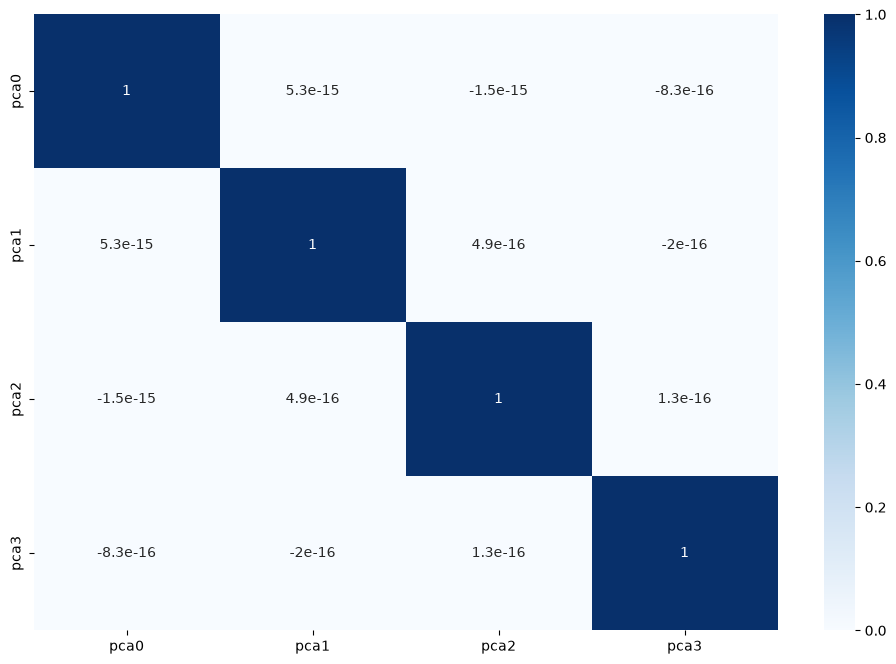

In [67]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    X_train_pca[['pca0', 'pca1', 'pca2', 'pca3']].corr(),
    annot=True,
    cmap='Blues'
)

plt.show()

We use a sparse method here, to save RAM.

In [76]:
svd = TruncatedSVD(n_components=25, random_state=42)

In [77]:
X_train_svd = svd.fit_transform(X_train_transformed)
X_validation_svd = svd.transform(X_validation_transformed)
X_test_svd = svd.transform(X_test_transformed)

## 2.1 Model training

In [78]:
lr_model = LogisticRegression(
        solver="lbfgs",
        max_iter=300
)

lr_model.fit(X_train_svd, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",300
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in

In [11]:
rf_model = RandomForestClassifier(
    n_estimators=50,
    random_state=42
)

rf_model.fit(X_train, y_train)

KeyboardInterrupt: 

In [9]:
cb_model = CatBoostClassifier(
    iterations=300,
    learning_rate=0.1,
    depth=6,
    loss_function="MultiClass",
    eval_metric="Accuracy",
    random_seed=42,
    verbose=50,
    task_type="GPU",
    devices="0"
)

cb_model.fit(X_train, y_train)

0:	learn: 0.0865769	total: 447ms	remaining: 2m 13s
50:	learn: 0.1843212	total: 19.1s	remaining: 1m 33s
100:	learn: 0.1996141	total: 37.7s	remaining: 1m 14s
150:	learn: 0.2089900	total: 56.3s	remaining: 55.5s
200:	learn: 0.2150904	total: 1m 14s	remaining: 36.9s
250:	learn: 0.2198668	total: 1m 33s	remaining: 18.2s
299:	learn: 0.2236220	total: 1m 51s	remaining: 0us


CatBoostClassifier(depth=6, devices='0', eval_metric='Accuracy', iterations=300, learning_rate=0.1, loss_function='MultiClass', random_seed=42, task_type='GPU', verbose=50)

## 2.2 Model evaluation

In [80]:
y_pred = lr_model.predict(X_test_svd)
accuracy = accuracy_score(y_test, y_pred)

print(f"Model Accuracy: {accuracy:.2f}")

Model Accuracy: 0.16


In [82]:
from sklearn.metrics import accuracy_score, f1_score
from sklearn.dummy import DummyClassifier
from sklearn.metrics import classification_report

# Your model
y_pred_train = lr_model.predict(X_train_svd)
y_pred_test = lr_model.predict(X_test_svd)

print(f"Train accuracy: {accuracy_score(y_train, y_pred_train):.3f}")
print(f"Test accuracy:  {accuracy_score(y_test, y_pred_test):.3f}")
print(f"Test macro-F1:  {f1_score(y_test, y_pred_test, average='macro'):.3f}")

# Majority-class baseline
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train_svd, y_train)
y_pred_dummy = dummy.predict(X_test_svd)

print(f"Majority baseline: {accuracy_score(y_test, y_pred_dummy):.3f}")

print(classification_report(y_test, y_pred_test, zero_division=0))

Train accuracy: 0.166
Test accuracy:  0.163
Test macro-F1:  0.101
Majority baseline: 0.024
              precision    recall  f1-score   support

           0       0.09      0.04      0.05      2123
           1       0.13      0.06      0.08      1373
           2       0.06      0.06      0.06      2643
           3       0.00      0.00      0.00       744
           4       0.20      0.25      0.22      2693
           5       0.16      0.15      0.16      2351
           6       0.30      0.53      0.38      2243
           7       0.15      0.20      0.17      1917
           8       0.07      0.07      0.07      3114
           9       0.03      0.01      0.02      3092
          10       0.15      0.11      0.13       969
          11       0.04      0.01      0.01      2876
          12       0.11      0.05      0.07      1561
          13       0.40      0.02      0.03       518
          14       0.23      0.48      0.31      2087
          15       0.17      0.11      0.13 

In [83]:
print("SVD components:", svd.n_components)
print(
    "Cumulative explained variance:",
    svd.explained_variance_ratio_.sum()
)

SVD components: 25
Cumulative explained variance: 0.937334976807594


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

lr_baseline = LogisticRegression(
    max_iter=1000,
    solver="lbfgs"
)

lr_baseline.fit(X_train_transformed, y_train)

y_pred = lr_baseline.predict(X_test_transformed)

print(f"Accuracy: {accuracy_score(y_test, y_pred):.3f}")
print(f"Macro-F1: {f1_score(y_test, y_pred, average='macro'):.3f}")